In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
from icecream import ic

import affine_tracer as aft

In [2]:
# generate synthetic data - true function as sample from the prior

np.random.seed(0)

#setting hyperparameters
l = 0.8
sig2 = 0.1
sig_ker = 1

# 2d grids of different resolutions - especially for multigrid 
n_grid = 5
n_test= n_grid * n_grid
n_f = 30
n_c = 10
n_train = n_f * n_f
n_data = n_train + n_test   

nx, ny = (n_f, n_f)
x = np.linspace(0, 1, nx)
y = np.linspace(0, 1, ny)
xv, yv = np.meshgrid(x, y, indexing='ij')
g_f = np.stack([xv.ravel(), yv.ravel()], axis=1)
Xtrain = g_f

nx, ny = (n_c, n_c)
x = np.linspace(0, 1, nx)
y = np.linspace(0, 1, ny)
xv, yv = np.meshgrid(x, y, indexing='ij')
g_c = np.stack([xv.ravel(), yv.ravel()], axis=1)

grids = [g_f, g_c]
A2 = aft.matker32(g_c, g_c, l = l, sig2 = sig_ker)
grids = [g_f, g_c]
x_g = np.linspace(0 , 1, n_grid)
xx, yy = np.meshgrid(x_g, x_g)
Xtest = np.vstack([xx.ravel(), yy.ravel()]).T

Ctrtr = aft.matker32(Xtrain, Xtrain, l = l, sig2= sig_ker)
Ctrts = aft.matker32(Xtest, Xtrain, l = l, sig2= sig_ker)
Ctsts = aft.matker32(Xtest, Xtest, l = l, sig2= sig_ker)

augmented_cov = np.block([[Ctrtr, Ctrts],[Ctrts.T, Ctsts]])
augmented_mu = np.zeros(n_data)
y_augmented = np.random.multivariate_normal(augmented_mu, augmented_cov)


ytrain_true = y_augmented[0:n_train]
ytrain = ytrain_true + np.random.normal(0, sig2, n_train)
ytest = y_augmented[n_train:]

In [3]:
# this is the linear system we are interested in solving, using a probabilistic iterative method
A = Ctrtr + sig2 * np.eye(n_train)
b = ytrain

# define prior mean and covariance 
x_mg = np.zeros(A.shape[0])
Sigma_mg = np.eye(A.shape[0]) 


#set up multigrid solver - define all the components
m_pres = 1
m_poss = 1
presmoother_solver = aft.gs_explicit
postsmoother_solver = aft.gs_explicit
restrictor_fn = aft.restrictor_nn_fn2
restrictor_mat = aft.restrictor_nn
interpolator_fn = aft.interpolator_nn_fn2
interpolator_mat = aft.interpolator_nn
exact_solver = aft.exact_solve
matrices = [aft.A_mat(A)]

multigrid2 = aft.multigrid_m_class(grids = grids, matrices = matrices, presmoother = presmoother_solver, postsmoother = postsmoother_solver, interpolator = interpolator_fn, interpolator_mat = interpolator_mat, restrictor = restrictor_fn, restrictor_mat = restrictor_mat, exact_solve = exact_solver)
total_iter = 3

#instead of computing mutigrid iteration directly as 
test_x = x_mg
for i in range(total_iter):
    test_x = multigrid2.v_cycle(grids= grids, matrices= matrices, b = b, u_0 = test_x, h = 2, m_pres = m_pres, m_poss = m_poss)

#use tracer to trace the computational graph, using x0 = tracer in the multigrid step
tracer = aft.polytree()
tx = tracer.nodes[0]
for i in range(total_iter):
    tx = multigrid2.v_cycle(grids= grids, matrices= matrices, b = b, u_0 = tx, h = 2, m_pres = m_pres, m_poss = m_poss)

#then compute posterior mean and covariance
x_mg = aft.get_mean(tracer, x_mg)
Sigma_mg = aft.get_cov(tracer, Sigma_mg)



In [4]:
# For the CAGP posterior, set up CAGP class
GPClass = aft.CAGP(Xtrain = Xtrain, ytrain = ytrain, sigma2 = sig2, Xtest = Xtest, l = l, sig_ker2 = 1, ytest = ytest)
iter = 25

# pre-compilation for equality saturation, this setup uses a stationary iterative method and thus we only need to trace one iteration of the multigrid
ic('starting equity saturation')
tracer_singleit = aft.polytree()
_ = multigrid2.v_cycle(grids= grids, matrices= matrices, b = b, u_0 = tracer_singleit.nodes[0], h = 2, m_pres = m_pres, m_poss = m_poss)
tracer_copy = tracer_singleit
ex_DV, val_dict = aft.get_DV_expr(tracer_copy, GPClass.Xtrdim, 2, GPClass.G, egglog_step2_runs = 17)
ex_VD, val_dict = aft.get_VD_expr(tracer_copy, GPClass.Xtrdim, 2, GPClass.G, egglog_step2_runs= 17)
compiled_sis_class = aft.compiled_sis(tracer, ex_VD, ex_DV, val_dict)


ic| 'init'
ic| 'starting equity saturation'
ic| 'step 1 done'
ic| i: 0
ic| i: 1
ic| i: 2
ic| i: 3
ic| i: 4
ic| i: 5
ic| i: 6
ic| i: 7
ic| i: 8
ic| i: 9
ic| i: 10
ic| i: 11
ic| i: 12
ic| i: 13
ic| i: 14
ic| i: 15
ic| i: 16
ic| 'step 2 done'
ic| 'step 1 done'
ic| i: 0
ic| i: 1
ic| i: 2
ic| i: 3
ic| i: 4
ic| i: 5
ic| i: 6
ic| i: 7
ic| i: 8
ic| i: 9
ic| i: 10
ic| i: 11
ic| i: 12
ic| i: 13
ic| i: 14
ic| i: 15
ic| i: 16
ic| 'step 2 done'


In [5]:
# computing the CAGP posterior
mean_mg2, cov_mg2 = GPClass.PLS_SIS(m = iter, compiled_sis = compiled_sis_class)
rmse_mg2 = GPClass.rmse_mg
nll_mg2 = GPClass.nll_mg

# also compute CAGP-CG and CAGP-GS posteriors as baselines
mean_cg, cov_cg = GPClass.PLS_CG(m = iter)
rmse_cg = GPClass.rmse_cg
nll_cg = GPClass.nll_cg

mean_gs, cov_gs = GPClass.PLS_GS(m = iter)
rmse_gs = GPClass.rmse_gs
nll_gs = GPClass.nll_gs

ic| i: 0
ic| i: 1
ic| i: 2
ic| i: 3
ic| i: 4
ic| i: 5
ic| i: 6
ic| i: 7
ic| i: 8
ic| i: 9
ic| i: 10
ic| i: 11
ic| i: 12
ic| i: 13
ic| i: 14
ic| i: 15
ic| i: 16
ic| i: 17
ic| i: 18
ic| i: 19
ic| i: 20
ic| i: 21
ic| i: 22
ic| i: 23
ic| i: 24
ic| i: 0
ic| i: 1
ic| i: 2
ic| i: 3
ic| i: 4
ic| i: 5
ic| i: 6
ic| i: 7
ic| i: 8
ic| i: 9
ic| i: 10
ic| i: 11
ic| i: 12
ic| i: 13
ic| i: 14
ic| i: 15
ic| i: 16
ic| i: 17
ic| i: 18
ic| i: 19
ic| i: 20
ic| i: 21
ic| i: 22
ic| i: 23
ic| i: 24
ic| i: 0
ic| i: 1
ic| i: 2
ic| i: 3
ic| i: 4
ic| i: 5
ic| i: 6
ic| i: 7
ic| i: 8
ic| i: 9
ic| i: 10
ic| i: 11
ic| i: 12
ic| i: 13
ic| i: 14
ic| i: 15
ic| i: 16
ic| i: 17
ic| i: 18
ic| i: 19
ic| i: 20
ic| i: 21
ic| i: 22
ic| i: 23
ic| i: 24


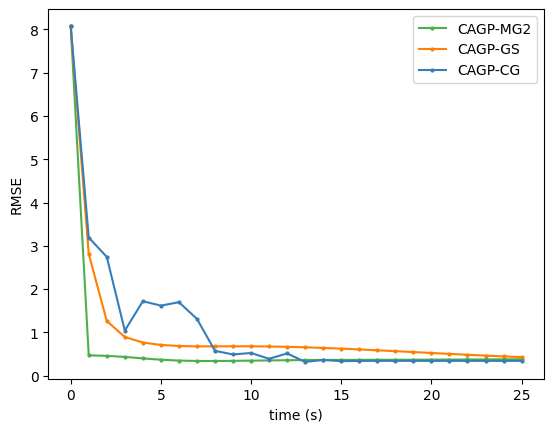

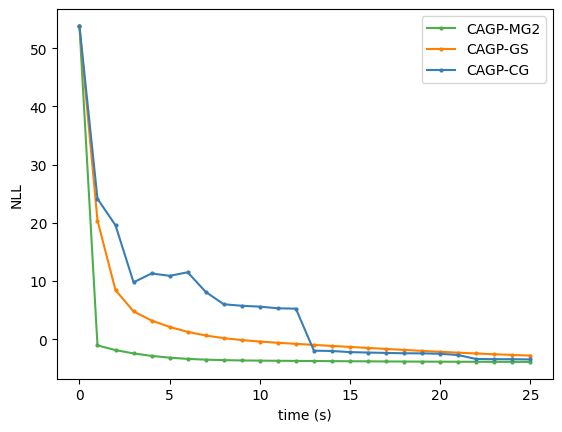

In [6]:
# plot RMSE and NLL for all three methods

CB_color_cycle = ['#377eb8', '#ff7f00', '#4daf4a',
                  '#f781bf', '#a65628', '#984ea3',
                  '#999999', '#e41a1c', '#dede00']

iters = np.arange(0, iter+1)
plt.plot(iters, rmse_mg2, label = 'CAGP-MG2', color = CB_color_cycle[2], marker = 'o', markersize = 2)
plt.plot(iters, rmse_gs, label = 'CAGP-GS', color = CB_color_cycle[1], marker = 'o', markersize = 2)
plt.plot(iters, rmse_cg, label = 'CAGP-CG', color = CB_color_cycle[0], marker = 'o', markersize = 2)
plt.legend()
plt.xlabel('time (s)')
plt.ylabel('RMSE')
plt.show()

plt.plot(iters, nll_mg2, label = 'CAGP-MG2', color = CB_color_cycle[2], marker = 'o', markersize = 2)
plt.plot(iters, nll_gs, label = 'CAGP-GS', color = CB_color_cycle[1], marker = 'o', markersize = 2)
plt.plot(iters, nll_cg, label = 'CAGP-CG', color = CB_color_cycle[0], marker = 'o', markersize = 2)
plt.legend()
plt.xlabel('time (s)')
plt.ylabel('NLL')
plt.show()